# Ensaio 1 · Envelope do sinal bruto nos dados CWRU

**Estudo:** Smith & Randall (2015), *Mechanical Systems and Signal Processing* 64–65: 100–131, Método 1.

**Hipótese:** no espectro de envelope, cada falha aparece na sua frequência teórica (pista externa ≈ 107 Hz, pista interna ≈ 162 Hz, esfera ≈ 141 Hz = 2×BSF) entre os 3 maiores picos. O arquivo sem defeito não mostra nenhum desses picos.

**Dados:** CWRU, lado acionado, 12 kHz, carga 0 hp. Rode antes `python data/download.py`.

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src.envelope import *

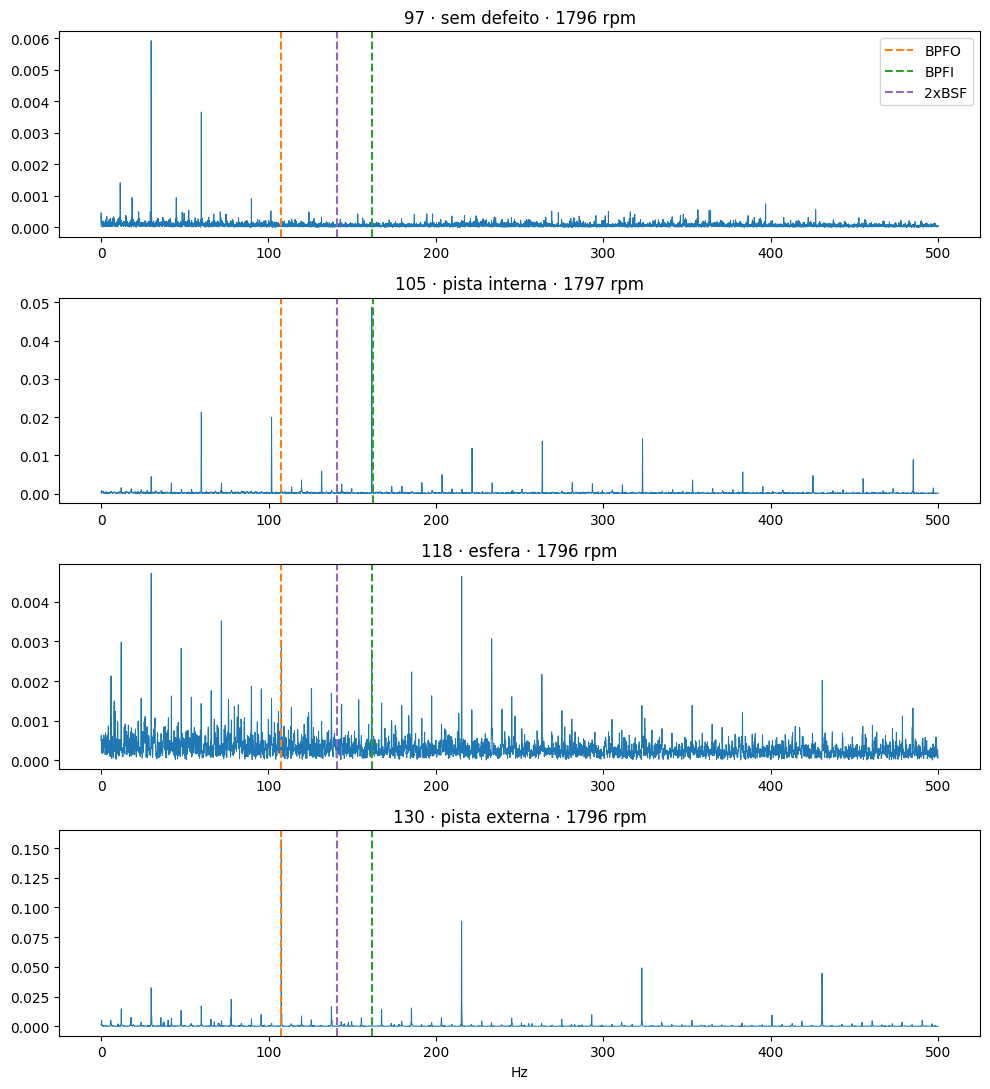

In [2]:
REC = {97: ("sem defeito", None), 105: ("pista interna", "BPFI"), 118: ("esfera", "2xBSF"), 130: ("pista externa", "BPFO")}
resultados = {}
fig, axes = plt.subplots(4, 1, figsize=(10, 11))
for ax, (n, (label, alvo)) in zip(axes, REC.items()):
    x, rpm = load_de(DATA_DIR / f"{n}.mat")
    fr, ff = fault_freqs(rpm)
    f, S = envelope_spectrum(x)
    resultados[n] = {k: peak_rank(f, S, ff[k]) for k in ["BPFO", "BPFI", "BSF", "2xBSF"]}
    sel = f < 500
    ax.plot(f[sel], S[sel], lw=0.7)
    for k, c in [("BPFO", "tab:orange"), ("BPFI", "tab:green"), ("2xBSF", "tab:purple")]:
        ax.axvline(ff[k], ls="--", color=c, label=k)
    ax.set_title(f"{n} · {label} · {rpm:.0f} rpm")
axes[0].legend(); axes[-1].set_xlabel("Hz"); plt.tight_layout()
plt.savefig("../results/ensaio1_envelopes.png", dpi=110)

In [3]:
for n, r in resultados.items():
    print(n, REC[n][0], {k: f"{v[0]:.1f} Hz · posição {v[1]}" for k, v in r.items()})
json.dump({str(k): v for k, v in resultados.items()}, open("../results/ensaio1.json", "w"), indent=1)

97 sem defeito {'BPFO': '108.4 Hz · posição 316', 'BPFI': '164.5 Hz · posição 340', 'BSF': '71.2 Hz · posição 19', '2xBSF': '142.9 Hz · posição 107'}
105 pista interna {'BPFO': '108.0 Hz · posição 50', 'BPFI': '161.7 Hz · posição 1', 'BSF': '71.9 Hz · posição 20', '2xBSF': '143.7 Hz · posição 22'}
118 esfera {'BPFO': '107.7 Hz · posição 6', 'BPFI': '161.6 Hz · posição 8', 'BSF': '71.9 Hz · posição 3', '2xBSF': '143.7 Hz · posição 29'}
130 pista externa {'BPFO': '107.6 Hz · posição 1', 'BPFI': '161.2 Hz · posição 241', 'BSF': '71.9 Hz · posição 36', '2xBSF': '143.4 Hz · posição 41'}


## Resultado

- **Pista externa (130):** pico nº 1 em 107,6 Hz. Bateu.
- **Pista interna (105):** pico nº 1 em 161,7 Hz. Bateu.
- **Sem defeito (97):** nenhuma frequência de falha no top 3. Bateu.
- **Esfera (118):** 2×BSF só na 29ª posição. **Não bateu.** Olhando a frequência básica (BSF), ela aparece em 3º lugar, como mostra o ensaio 2.

Pergunta que sobra: os outros métodos do mesmo artigo acham a esfera? → ensaio 2.